<a href="https://colab.research.google.com/github/gee666thu/r5-machine-learning-lab/blob/main/modf%2099.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

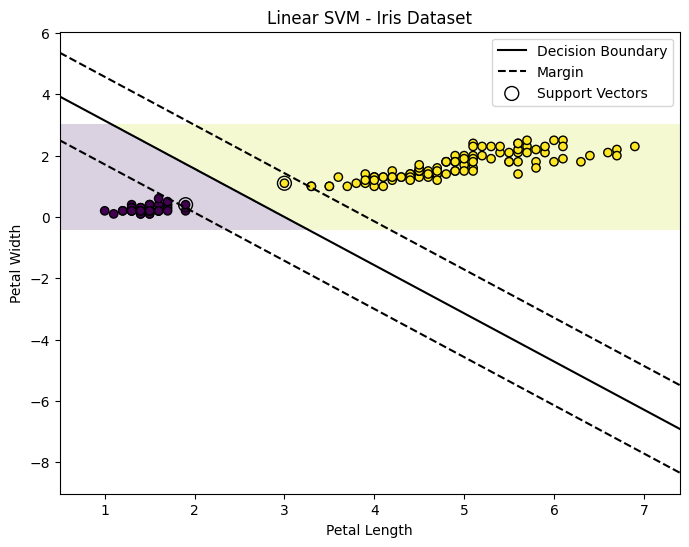

In [9]:
#Set graph range
plt.figure(figsize=(8, 6))
x_min, x_max = X[:, 0].min()-0.5, X[:, 0].max()+0.5
y_min, y_max = X[:, 1].min()-0.5, X[:, 1].max()+0.5

#Create grid
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

#Plot regions and data points
plt.contourf(xx, yy, Z, alpha=0.2)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k")

#Calculate boundary and margins
w, b = model.coef_[0], model.intercept_[0]
x = np.linspace(x_min, x_max, 100)
line = -(w[0]*x+b)/w[1]
margin = np.sqrt(1+(w[0]/w[1])**2)/np.linalg.norm(w)

#Draw boundary and margins
plt.plot(x, line, "k-", label="Decision Boundary")
plt.plot(x, line+margin, "k--", label="Margin")
plt.plot(x, line-margin, "k--")

#Show support vectors
plt.scatter(model.support_vectors_[:, 0],
             model.support_vectors_[:, 1],
            s=100, facecolors="none",
            edgecolors="black", label="Support Vectors")

#Add labels and display
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Linear SVM - Iris Dataset")
plt.legend()
plt.show()

In [10]:
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Accuracy: 100.0 %
